In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent aesthetics
plt.style.use('default')
sns.set_theme(style='whitegrid', palette='husl')
np.random.seed(42)

In [15]:
errors_um = np.array([12, 15, 14, 11, 16, 13, 15, 12, 14, 18])
np.ptp(errors_um)
mean = errors_um.sum()/len(errors_um)
deviations = errors_um - mean
variance = (deviations**2).sum()/(len(errors_um)-1)

print(variance)
print(variance == np.var(errors_um, ddof=1))

True
4.444444444444445
True


In [12]:
np.var(errors_um,ddof=0)

np.float64(4.0)

In [18]:
standard_deviation = np.std(errors_um,ddof=1)
standard_deviation

np.float64(2.1081851067789197)

In [21]:
std_boundary = [mean-standard_deviation,mean+standard_deviation]

within_1_sd = np.mean((errors_um >= (mean - standard_deviation)) & (errors_um <= (mean + standard_deviation))) * 100
print(f"Percentage of points within 1 SD: {within_1_sd:.1f}%")

Percentage of points within 1 SD: 80.0%


In [33]:
load_times = np.array([
    180, 195, 205, 210, 215, 220, 222, 225, 228, 230,
    235, 238, 240, 245, 250, 255, 260, 275, 450, 520
])
q1 = np.percentile(load_times,25)
q2 = np.percentile(load_times,50)
q3 = np.percentile(load_times,75)

iqr = q3-q1

l_fence = q1-1.5*iqr
r_fence = q3+1.5*iqr

outliers = [x for x in load_times if x <l_fence or x > r_fence]

print("Outliers:")
for x in outliers:
    print(f"{x} at index {list(load_times).index(x)}")

Outliers:
450 at index 18
520 at index 19


In [57]:
clean_scores = np.array([72, 75, 78, 80, 82, 83, 85, 87, 88, 90, 92, 95])
# Contaminated with an input entry typo: a score of 10 and a score of 250
corrupted_scores = np.append(clean_scores, [10, 250])

In [58]:
def summarize_spread(data):
    return {"range": np.ptp(data),
            "std": np.std(data,ddof=1),
            "iqr": (np.percentile(data,75)-np.percentile(data,25))}
def percent_change(orig,new):
    return  (new-orig)/orig

In [64]:
clean_summary = summarize_spread(clean_scores)
corrupted_summary = summarize_spread(corrupted_scores)

print(f"Change in range: {percent_change(clean_summary["range"],corrupted_summary["range"])*100:.1f}%")
print(f"Change in standard deviation: {percent_change(clean_summary["std"],corrupted_summary["std"])*100:.1f}%")
print(f"Change in IQR: {percent_change(clean_summary["iqr"],corrupted_summary["iqr"])*100:.1f}%")


Change in range: 943.5%
Change in standard deviation: 626.3%
Change in IQR: 22.2%


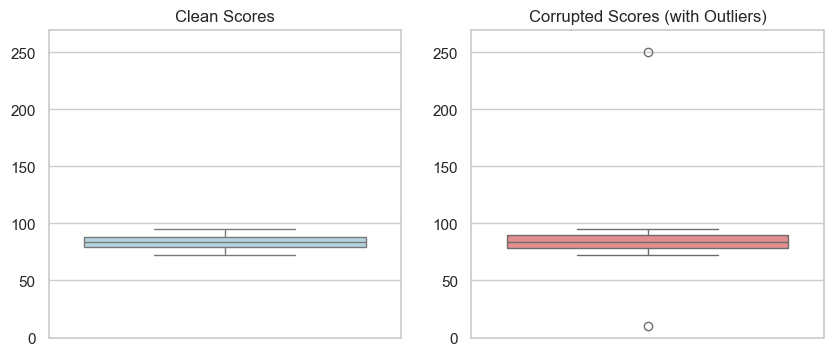

In [72]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=clean_scores,ax=ax1,color='lightblue')
ax1.set_title('Clean Scores')
ax1.set_ylim(0,270)

sns.boxplot(y=corrupted_scores,ax=ax2,color='lightcoral')
ax2.set_title('Corrupted Scores (with Outliers)')
ax2.set_ylim(0,270)
plt.show()